# RUSH 4 — Segmentation des utilisateurs Instagram
## Audit des données, exploration et premières briques de scoring

> **En une phrase.** Ce notebook vérifie si le temps passé sur Instagram est lié au stress, au bonheur et au sommeil, puis construit une première segmentation simple et utilisable par une équipe produit.

**Question du département :** comment l'usage d'Instagram est-il relié au stress, au bonheur et au sommeil, et peut-on en déduire des segments de users utiles aux équipes produit ?

### Résumé exécutif (version courte)

1. **Le temps d'usage est le signal le plus fort.** Plus il augmente, plus le stress moyen monte et plus le bonheur moyen baisse.
2. **Le sommeil ne montre aucun lien** avec le temps d'usage dans ces données.
3. **Les informations socio-démographiques n'expliquent presque rien** du bien-être.
4. **Un modèle basé seulement sur le temps** est presque aussi performant qu'un modèle qui utilise toutes les variables.
5. **La segmentation la plus utile est un découpage simple par temps**, pas un clustering complexe.

Ces résultats décrivent des **associations**, pas des causes. Ils sont valables pour ce jeu de données synthétique, pas pour tous les utilisateurs d'Instagram.

### Ce que fait ce notebook

1. Compare les deux fichiers et choisit les colonnes fiables.
2. Nettoie les erreurs détectables.
3. Cherche les liens entre usage et bien-être, y compris les liens absents.
4. Fabrique un score de bien-être et une cible « haut bien-être ».
5. Teste si un modèle ou une segmentation apporte quelque chose de plus qu'un simple classement par temps.
6. Rappelle les limites et les règles de protection des données.

> **Règle appliquée dès ce notebook :** aucune ligne individuelle n'est affichée. Toutes les sorties sont des agrégats. Les identifiants ne servent qu'à compter.

### Ce que ce notebook ne fait pas

- Il ne prouve pas qu'Instagram **cause** le stress ou le malheur.
- Il ne produit pas un **diagnostic médical** ni un score clinique.
- Il ne permet pas de **cibler les mineurs** ou les personnes selon leur santé.
- Il ne remplace pas une validation sur des données réelles.

### Cadrage : critères de réussite fixés *avant* les résultats

| Critère | Ce que ça veut dire | Comment on vérifie |
|---|---|---|
| **Utilisable pour tous** | on peut ranger n'importe quel utilisateur avec des informations disponibles pour tous | fonction `assign_usage_segment()` |
| **Stable** | deux échantillons donnent à peu près les mêmes groupes | ARI split-half |
| **Segments assez grands** | les groupes sont assez gros et différents pour être utiles | taille minimale, silhouette |
| **Apporte un plus** | la segmentation fait mieux que le simple classement par temps | ΔAUC, ΔR², ARI |
| **Facile à expliquer** | une équipe produit peut comprendre et utiliser les groupes | liste des variables |
| **Conforme et prudent** | pas de donnée de santé dans les groupes, pas de ciblage des mineurs, pas de petit groupe | audit final |

### Protocole

- **Extrait A** = `instagram_usage_lifestyleSafe.csv` (référence pour les dates et le comportement).
- **Extrait B** = `instagram_users_lifestyleSafe.csv` (retenu pour les champs socio-démographiques : éducation, emploi, situation familiale ; voir §1).
- **Population** : 200 000 users, panneau auto-déclaré pour les variables de bien-être.
- **Graine aléatoire** : 42 partout, pour que les résultats soient reproductibles.


### Guide de lecture

| Repère | À quoi ça sert |
|---|---|
| `> **En clair.**` | Explication simple, sans jargon. Si vous ne lisez qu'une chose, lisez celle-ci. |
| `> **À retenir.**` | Conclusion courte de la partie. |
| Texte normal | Méthode, choix et précautions. |
| Code | Calculs reproductibles. On peut les ignorer en première lecture. |

### Hypothèses testées

| # | Hypothèse | Comment on la teste | Où |
|---|---|---|---|
| H1 | Plus le temps d'usage augmente, plus le stress monte et plus le bonheur baisse. | corrélations et déciles | §3 |
| H2 | Le sommeil n'est pas lié au temps d'usage dans ces données. | corrélations et déciles | §3 |
| H3 | Les variables socio-démographiques n'expliquent pas le bien-être. | η² et corrélations | §3.3 |
| H4 | Une segmentation simple par seuils est plus utile et plus stable qu'un clustering. | KMeans vs seuils, ARI, η² | §7 à §9 |

**Comment on décide.** Une hypothèse n'est pas « vraie » parce qu'elle nous plaît : on regarde un chiffre, on le compare à une référence, et on accepte aussi les résultats nuls.

**Résultat global (détail plus bas) :** H1 est confirmée, H2 est confirmée (lien nul), H3 est confirmée, et H4 est confirmée pour la stabilité et la lisibilité. Le gain de prédiction par rapport au temps seul reste faible.

### Vocabulaire minimal

- **Feature** : information fabriquée à partir des données (ex. minutes par jour).
- **Cible** : ce que l'on cherche à expliquer ou à prédire (ici, le stress, le bonheur ou le « haut bien-être »).
- **Segmentation** : découpage des utilisateurs en groupes.
- **Cluster** : groupe trouvé automatiquement par un algorithme.
- **AUC** : qualité d'un classement (0,5 = hasard ; 1 = parfait).
- **η²** : part des différences de bien-être expliquée par un groupe (0 = aucun lien ; 1 = tout).

Le lexique complet est en fin de notebook (§11.5).


## 0. Préparer l'environnement

> **En clair.** Cette partie installe les outils et fixe les règles pour que le notebook puisse être relancé par quelqu'un d'autre, sans dépendre d'un réglage caché.

Dépendances : `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `scipy`. Pas de `seaborn` requis.


In [8]:
%pip install numpy pandas matplotlib scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from pathlib import Path
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, brier_score_loss,
    silhouette_score, adjusted_rand_score, r2_score,
)
from sklearn.inspection import permutation_importance

try:
    from IPython.display import display
except ImportError:          # permet d'exécuter le notebook comme un script
    display = print

RANDOM_STATE = 42
DATA_DIR = Path(".")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_fig(name: str, dpi: int = 120) -> None:
    '''Sauvegarde robuste : les dossiers synchronisés (OneDrive) peuvent verrouiller un fichier.'''
    path = (FIG_DIR / name).resolve()
    for _ in range(3):
        try:
            plt.savefig(path, dpi=dpi)
            return
        except OSError:
            time.sleep(0.5)
    plt.savefig(path, dpi=dpi)

print("Environnement prêt.")


Environnement prêt.


### 0.1 Conclusion — un socle reproductible

> **À retenir.** Le notebook peut être relancé dans le même ordre, avec la même graine aléatoire, sans afficher de données individuelles.

- Une seule graine (`RANDOM_STATE = 42`) et des chemins relatifs : le notebook peut être rejoué de bout en bout.
- `save_fig()` protège l'écriture des figures sur un dossier synchronisé (OneDrive) ; aucune figure n'est indispensable au raisonnement.
- Toutes les sorties sont agrégées : aucune ligne individuelle, aucun identifiant affiché.
- Les versions de bibliothèques sont celles de l'environnement d'exécution ; le rendu peut varier légèrement sur une autre machine.

**Transition.** Le socle est posé ; on peut auditer les deux extraits sans les concaténer.


## 1. Vérifier les deux fichiers de données

> **En clair.** Nous avons deux fichiers qui décrivent les mêmes 200 000 utilisateurs. Avant de les utiliser, on vérifie s'ils disent la même chose et on choisit la version la plus cohérente pour chaque colonne.

On charge les deux fichiers **sans les concaténer** : ce sont deux versions du même panneau, pas deux populations.


In [10]:
path_a = DATA_DIR / "data/instagram_usage_lifestyleSafe.csv"
path_b = DATA_DIR / "data/instagram_users_lifestyleSafe.csv"

raw_a = pd.read_csv(path_a)
raw_b = pd.read_csv(path_b)

audit = pd.DataFrame(
    {
        "Extrait A (usage)": [
            raw_a.shape[0], raw_a.shape[1], raw_a["user_id"].nunique(),
            int(raw_a.duplicated().sum()), int(raw_a.isna().sum().sum()),
        ],
        "Extrait B (users)": [
            raw_b.shape[0], raw_b.shape[1], raw_b["user_id"].nunique(),
            int(raw_b.duplicated().sum()), int(raw_b.isna().sum().sum()),
        ],
    },
    index=["Lignes", "Colonnes", "user_id uniques", "Lignes dupliquées", "Valeurs manquantes"],
)
display(audit)
print("Colonnes identiques :", list(raw_a.columns) == list(raw_b.columns))
print("Mêmes user_id, même ordre :", bool((raw_a["user_id"].values == raw_b["user_id"].values).all()))
print("Aucune valeur manquante :", raw_a.isna().sum().sum() == 0 and raw_b.isna().sum().sum() == 0)


,Extrait A (usage),Extrait B (users)
Lignes,200000,200000
Colonnes,58,58
user_id uniques,200000,200000
Lignes dupliquées,0,0
Valeurs manquantes,0,0


Colonnes identiques : True
Mêmes user_id, même ordre : True
Aucune valeur manquante : True


### 1.1 Les deux fichiers racontent-ils la même chose ?

Un seul extrait doit servir de référence. On quantifie d'abord les divergences, puis on teste leur **cohérence interne** (dates, modalités, heures de travail).


In [11]:
def divergence_profile(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in a.columns:
        if pd.api.types.is_numeric_dtype(a[col]):
            diff = ~np.isclose(a[col].astype(float), b[col].astype(float), equal_nan=True)
            kind = "numérique"
        else:
            diff = a[col].fillna("NA").astype(str) != b[col].fillna("NA").astype(str)
            kind = "catégorielle"
        n = int(diff.sum())
        if n:
            rows.append({"Colonne": col, "Type": kind, "Lignes divergentes": n,
                         "% divergentes": round(100 * n / len(a), 2)})
    return pd.DataFrame(rows).sort_values("Lignes divergentes", ascending=False)

divergences = divergence_profile(raw_a, raw_b)
display(divergences)

# Contrôles de cohérence internes
checks = []
for name, frame in {"A": raw_a, "B": raw_b}.items():
    login_year = pd.to_datetime(frame["last_login_date"], errors="coerce").dt.year
    no_job = frame["employment_status"].isin(["Unemployed", "Not employed"])
    checks.append({
        "Extrait": name,
        "Création > année de dernière connexion": int((frame["account_creation_year"] > login_year).sum()),
        "Création en 2026": int((frame["account_creation_year"] == 2026).sum()),
        "Modalités d'éducation": frame["education_level"].nunique(),
        "Heures trav. moy. des sans-emploi": round(frame.loc[no_job, "weekly_work_hours"].mean(), 1),
    })
display(pd.DataFrame(checks).set_index("Extrait"))

print("Modalités d'éducation dans B :")
print(raw_b["education_level"].value_counts().to_string())


,Colonne,Type,Lignes divergentes,% divergentes
5,account_creation_year,numérique,31772,15.890
0,employment_status,catégorielle,18913,9.460
4,weekly_work_hours,numérique,18912,9.460
2,relationship_status,catégorielle,6623,3.310
3,has_children,catégorielle,5329,2.660
1,education_level,catégorielle,1203,0.600


,Création > année de dernière connexion,Création en 2026,Modalités d'éducation,Heures trav. moy. des sans-emploi
Extrait,,,,
A,0,0,6,39.900
B,3724,3768,9,19.500


Modalités d'éducation dans B :
education_level
Bachelor’s      70355
High school     49615
Some college    40168
Master’s        23831
Other           10062
PhD              4766
Secondary         575
High School       329
Bachelor          299


### 1.2 Quel fichier garder pour chaque colonne ?

> **En clair.** Pour chaque colonne, on choisit la version la plus cohérente. Un champ marqué « Non » dans la dernière colonne n'est pas forcément inutile : il peut servir à décrire les utilisateurs sans entrer dans le modèle.

| Champ | Source retenue | Justification | Utilisé dans le modèle ? |
|---|---|---|---|
| `account_creation_year` | **A** | B contient 3 724 créations postérieures à la dernière connexion et 3 768 créations en 2026 ; A n'en a aucune. | Oui, via `account_age_years` |
| `education_level` | **B harmonisé** | A a replié 1 203 libellés (`Secondary`, `High School`, `Bachelor`) dans `PhD` : incohérent. B les restaure ; on normalise vers 6 modalités canoniques. Réserve : B laisse encore 8 828 mineurs en Bachelor's/Master's. | Non (η² ≈ 0 sur le bien-être) |
| `employment_status` | **B** | A donne un statut actif à des mineurs (18 464 mineurs à plus de 20 h/semaine, moyenne 40 h) ; B place les 18 913 mineurs en `Not employed`. | Non (η² ≈ 0) |
| `weekly_work_hours` | **Aucune (exclu)** | A attribue ~40 h/semaine aux mineurs ; B les met à 0 h. Le champ n'a aucun pouvoir explicatif → on l'écarte du modèle. | Non |
| `relationship_status`, `has_children` | **B** | A contient 6 623 mineurs mariés/divorcés/veufs et 5 329 mineurs avec enfants ; B corrige ces combinaisons. | Non (η² ≈ 0) |
| Variables de comportement, bien-être | **A** | Identiques dans les deux extraits. | Oui (bien-être = cible, jamais feature) |

**Argument clé pour la soutenance :** les champs divergents non utilisés comme features ont un η² ≈ 0 sur les trois indicateurs de bien-être (§3.3). Le seul champ divergent utilisé, `account_age_years`, a une importance quasi nulle dans le modèle (§6.2). Le choix de source ne change donc **aucune conclusion** sur le lien usage ↔ bien-être ; il ne change que le descriptif socio-démographique.

**Champs écartés d'emblée :**
- `app_name` : constante (« Instagram »).
- `daily_steps_count` : quasi constante (amplitude relative ≈ 10 %), donc presque aucune information.
- `user_engagement_score` : construit comme une intensité par minute (corr. ≈ 0,99 avec notre ratio interactions/minute) ; l'utiliser comme prédicteur serait circulaire. On reconstruit nos propres ratios.


In [12]:
num = raw_a.select_dtypes(include=np.number)
quality = pd.DataFrame({
    "min": num.min(), "max": num.max(), "moyenne": num.mean(), "écart-type": num.std(),
})
quality["amplitude / |moyenne|"] = ((quality["max"] - quality["min"]) / (quality["moyenne"].abs() + 1e-9))
display(quality[quality["amplitude / |moyenne|"] < 0.20].round(2))

constant_cols = [c for c in raw_a.columns if raw_a[c].nunique(dropna=False) == 1]
print("Colonnes constantes :", constant_cols)

identity_gap = (raw_a["sessions_per_day"] * raw_a["average_session_length_minutes"]
                - raw_a["daily_active_minutes_instagram"]).abs()
print(f"Écart max 'sessions × durée de session − minutes actives' : {identity_gap.max():.6f} min")

n_floor = int((raw_a["daily_active_minutes_instagram"] == 5).sum())
print(f"Utilisateurs à exactement 5,0 min/jour : {n_floor:,} ({n_floor / len(raw_a):.1%})")
print("→ valeur plancher de censure, pas une mesure continue : à flaguer.")


,min,max,moyenne,écart-type,amplitude / |moyenne|
daily_steps_count,"7,629.000","8,429.000","8,000.120",89.110,0.100
account_creation_year,"2,010.000","2,025.000","2,017.510",4.610,0.010


Colonnes constantes : ['app_name']
Écart max 'sessions × durée de session − minutes actives' : 2.400000 min
Utilisateurs à exactement 5,0 min/jour : 10,768 (5.4%)
→ valeur plancher de censure, pas une mesure continue : à flaguer.


### 1.3 Conclusion — que retenir de l'audit ?

> **À retenir.** Les deux fichiers sont deux versions du même panneau. On garde B pour les informations socio-démographiques et A pour les dates et le comportement.

- Les deux extraits ont exactement **200 000 lignes**, **58 colonnes**, **0 doublon**, **0 valeur manquante** et les mêmes `user_id` dans le même ordre : ce sont deux versions d'un même panneau, pas deux populations.
- **6 colonnes divergent**, de 1 203 lignes (`education_level`) à 31 772 lignes (`account_creation_year`).
- **B est retenu pour les 4 champs socio-démographiques** : il corrige des combinaisons impossibles chez les mineurs que A conserve (6 623 mariages/divorces/veuvages, 5 329 enfants, 18 464 mineurs à plus de 20 h/semaine).
- **A est retenu pour les dates et le comportement** : B contient 3 724 créations après la dernière connexion et 3 768 créations en 2026, ce qui est impossible ; A n'en a aucune.
- Les champs divergents ne sont pas des features (sauf `account_age_years`, d'importance quasi nulle) : le choix A/B ne peut pas changer la relation usage ↔ bien-être.

**Transition.** Le périmètre est fixé ; on peut nettoyer sans masquer les anomalies.


## 2. Nettoyer les données sans les déformer

> **En clair.** Nettoyer ne veut pas dire supprimer tout ce qui est extrême. On corrige seulement ce qui est **prouvé faux** (doublons, incohérences, libellés), et on garde le reste.

### 2.1 Les règles de nettoyage

Le nettoyage reste **minimal et traçable** : on ne corrige que ce qui est démontrable. Les valeurs extrêmes plausibles (gros utilisateurs, gros comptes) sont conservées : les supprimer fabriquerait l'histoire qu'on cherche à mesurer.


In [13]:
EDU_MAP = {"Secondary": "High school", "High School": "High school", "Bachelor": "Bachelor’s"}
SOCIO_B = ["employment_status", "relationship_status", "has_children"]

df = raw_a.copy()
for col in SOCIO_B:
    df[col] = raw_b[col]        # B corrige les combinaisons impossibles chez les mineurs
df["education_level"] = raw_b["education_level"].replace(EDU_MAP)   # récupère les 1 203 libellés écrasés
df["last_login_date"] = pd.to_datetime(df["last_login_date"])
df["is_minor"] = df["age"] < 18
df["account_age_years"] = 2026 - df["account_creation_year"]
df["usage_floor_flag"] = (df["daily_active_minutes_instagram"] == 5).astype(int)

DROP_COLS = ["app_name", "daily_steps_count", "weekly_work_hours"]
df = df.drop(columns=DROP_COLS)

print("Colonnes supprimées :", DROP_COLS)
print("Champs socio-démographiques repris de B :", SOCIO_B + ["education_level"])
print("\nÉducation après harmonisation :")
print(df["education_level"].value_counts().to_string())
print(f"\nMineurs (13–17 ans) : {int(df['is_minor'].sum()):,} ({df['is_minor'].mean():.1%})")
print(f"Utilisateurs à 5,0 min/jour : {int(df['usage_floor_flag'].sum()):,}")
print(f"Dimensions finales : {df.shape[0]:,} × {df.shape[1]}")


Colonnes supprimées : ['app_name', 'daily_steps_count', 'weekly_work_hours']
Champs socio-démographiques repris de B : ['employment_status', 'relationship_status', 'has_children', 'education_level']

Éducation après harmonisation :
education_level
Bachelor’s      70654
High school     50519
Some college    40168
Master’s        23831
Other           10062
PhD              4766

Mineurs (13–17 ans) : 18,913 (9.5%)
Utilisateurs à 5,0 min/jour : 10,768
Dimensions finales : 200,000 × 58


### 2.2 Conclusion — un nettoyage minimal et justifié

> **À retenir.** On corrige les incohérences prouvées, on garde les cas extrêmes plausibles, et on signale les valeurs limites comme les 5,0 min/jour.

- **3 colonnes supprimées** : `app_name` (constante), `daily_steps_count` (quasi constante, amplitude relative ≈ 10 %), `weekly_work_hours` (incohérent et sans pouvoir explicatif).
- **4 champs socio-démographiques** viennent de B : `employment_status`, `relationship_status`, `has_children` et `education_level`. `weekly_work_hours` est également divergent mais il est écarté.
- **10 768 users (5,4 %)** sont exactement à 5,0 min/jour : valeur plancher probable, conservée et flaguée (`usage_floor_flag`), jamais supprimée.
- **18 913 users (9,5 %)** sont mineurs : ils restent dans l'analyse descriptive mais ne doivent jamais servir à un ciblage produit.
- Le jeu final garde **200 000 lignes et 58 colonnes**, sans valeur manquante ni doublon.
- Les valeurs extrêmes plausibles sont conservées : les supprimer fabriquerait l'histoire que l'on cherche à mesurer.


## 3. Explorer les liens entre usage et bien-être

> **En clair.** On regarde si le temps passé sur l'application et le bien-être évoluent ensemble. Une corrélation proche de +1 signifie « les deux montent ensemble » ; proche de -1, « l'un monte quand l'autre descend » ; proche de 0, « aucun lien simple ».

### 3.1 À quoi ressemblent les données ?

On regarde d'abord la forme des variables de bien-être et du temps d'usage : elle conditionne le choix des transformations et des modèles.


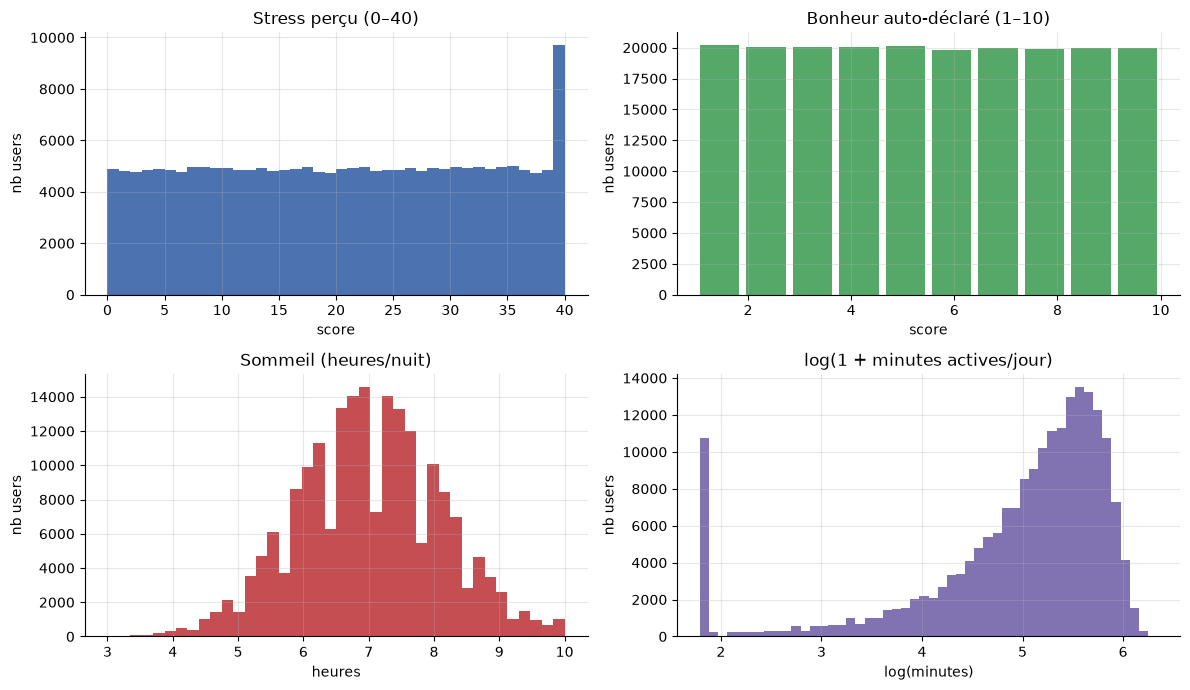

,count,mean,std,min,25%,50%,75%,max
perceived_stress_score,"200,000.000",20.020,11.820,0.000,10.000,20.000,30.000,40.000
self_reported_happiness,"200,000.000",5.490,2.870,1.000,3.000,5.000,8.000,10.000
sleep_hours_per_night,"200,000.000",7.000,1.100,3.000,6.300,7.000,7.700,10.000
daily_active_minutes_instagram,"200,000.000",188.730,110.170,5.000,102.000,187.000,272.000,565.000


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].hist(df["perceived_stress_score"], bins=40, color="#4C72B0")
axes[0, 0].set(title="Stress perçu (0–40)", xlabel="score", ylabel="nb users")
axes[0, 1].hist(df["self_reported_happiness"], bins=10, color="#55A868", rwidth=0.85)
axes[0, 1].set(title="Bonheur auto-déclaré (1–10)", xlabel="score", ylabel="nb users")
axes[1, 0].hist(df["sleep_hours_per_night"], bins=40, color="#C44E52")
axes[1, 0].set(title="Sommeil (heures/nuit)", xlabel="heures", ylabel="nb users")
axes[1, 1].hist(np.log1p(df["daily_active_minutes_instagram"]), bins=50, color="#8172B2")
axes[1, 1].set(title="log(1 + minutes actives/jour)", xlabel="log(minutes)", ylabel="nb users")
plt.tight_layout()
save_fig("01_distributions.png", dpi=120)
plt.show()

display(df[["perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night",
             "daily_active_minutes_instagram"]].describe().T.round(2))


**Lecture.** Le stress est presque uniforme sur 0–40 ; le bonheur est uniforme sur 1–10. Ces deux variables ont donc été générées indépendamment l'une de l'autre (r ≈ 0). Le temps d'usage est étalé de 5 à 565 min avec un pic artificiel à 5,0 min.


### 3.2 Les variables bougent-elles ensemble ?

On sépare bien-être (cibles) et usage (prédicteurs). `user_engagement_score` est gardé ici uniquement pour diagnostic, pas comme feature.


,perceived_stress_score,self_reported_happiness,sleep_hours_per_night
daily_active_minutes_instagram,0.830,-0.370,0.000
likes_given_per_day,0.820,-0.370,0.000
stories_viewed_per_day,0.810,-0.350,0.000
time_on_feed_per_day,0.810,-0.360,-0.000
comments_written_per_day,0.790,-0.350,0.000
time_on_reels_per_day,0.780,-0.350,-0.000
dms_received_per_week,0.770,-0.350,0.000
time_on_messages_per_day,0.750,-0.330,0.000
ads_viewed_per_day,0.750,-0.330,-0.000
dms_sent_per_week,0.750,-0.340,0.000


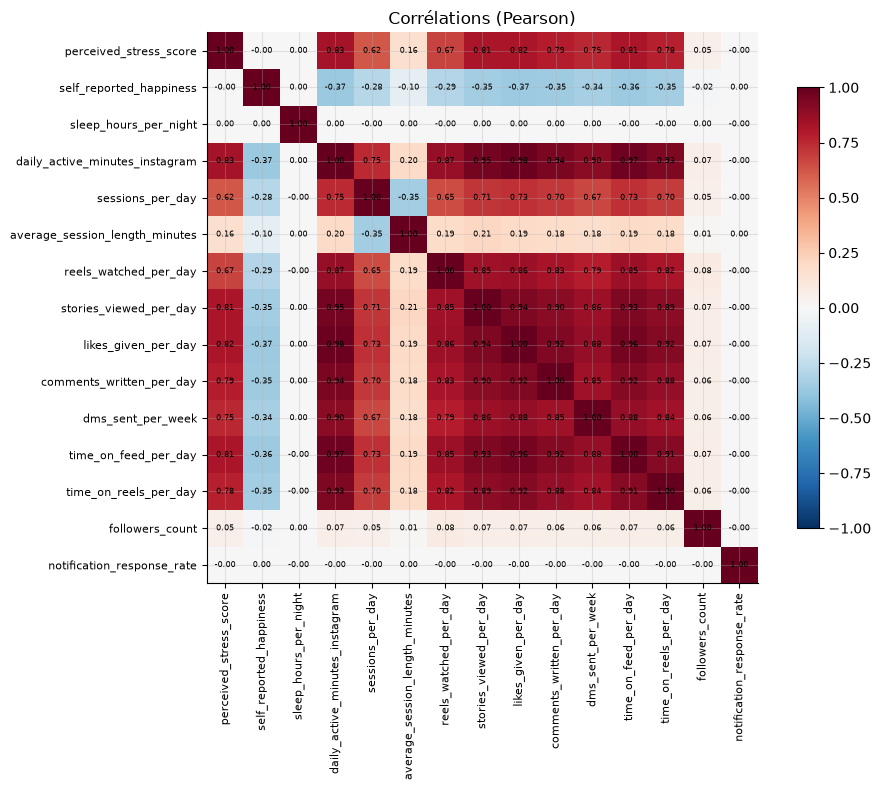

In [15]:
wellbeing_cols = ["perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night"]

usage_cols = [
    "daily_active_minutes_instagram", "sessions_per_day", "average_session_length_minutes",
    "posts_created_per_week", "reels_watched_per_day", "stories_viewed_per_day",
    "likes_given_per_day", "comments_written_per_day", "dms_sent_per_week", "dms_received_per_week",
    "ads_viewed_per_day", "time_on_feed_per_day", "time_on_explore_per_day",
    "time_on_messages_per_day", "time_on_reels_per_day", "followers_count", "following_count",
    "notification_response_rate", "user_engagement_score",
]

corr = df[wellbeing_cols + usage_cols].corr()
display(corr.loc[wellbeing_cols, usage_cols].T.round(2)
        .sort_values("perceived_stress_score", ascending=False))

# Heatmap lisible
hm_cols = wellbeing_cols + [
    "daily_active_minutes_instagram", "sessions_per_day", "average_session_length_minutes",
    "reels_watched_per_day", "stories_viewed_per_day", "likes_given_per_day",
    "comments_written_per_day", "dms_sent_per_week", "time_on_feed_per_day",
    "time_on_reels_per_day", "followers_count", "notification_response_rate",
]
hm = df[hm_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(hm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(hm_cols))); ax.set_xticklabels(hm_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(hm_cols))); ax.set_yticklabels(hm_cols, fontsize=8)
for i in range(len(hm_cols)):
    for j in range(len(hm_cols)):
        ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax.set_title("Corrélations (Pearson)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
save_fig("02_correlation_matrix.png", dpi=120)
plt.show()


### 3.3 Les liens sont-ils simples ? Y a-t-il des liens nuls ?

> **En clair.** On vérifie si la relation est régulière ou si elle change de forme, et on cherche aussi les liens **absents**. Un lien nul est un résultat utile, pas un échec.

Deux questions distinctes :
1. La relation au temps est-elle monotone ou saturante ? (utile pour choisir `log(minutes)` et pour le discours produit)
2. Quels indicateurs n'ont **aucun** lien avec l'usage ? Un lien nul est un résultat, pas un échec.

**Deux outils simples :**
- la **corrélation** pour les variables chiffrées : proche de 0 = pas de lien simple ;
- le **η²** pour les groupes (catégories) : proche de 0 = le groupe n'explique presque rien.


,minutes,stress,happiness,sleep
usage_decile,,,,
0,12.800,4.810,7.710,7.000
1,61.200,8.100,6.480,6.990
2,102.360,11.070,5.870,7.000
3,137.670,14.460,5.620,7.000
4,170.940,18.220,5.530,6.990
5,203.780,22.050,5.480,6.990
6,237.430,25.720,5.350,7.000
7,272.570,29.010,5.090,7.000
8,313.350,31.940,4.480,7.010


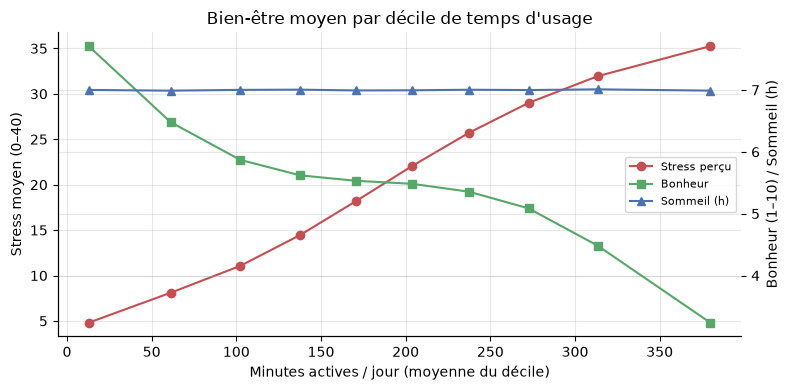

In [16]:
binned = df.copy()
binned["usage_decile"] = pd.qcut(binned["daily_active_minutes_instagram"], 10,
                                 labels=False, duplicates="drop")
deciles = binned.groupby("usage_decile").agg(
    minutes=("daily_active_minutes_instagram", "mean"),
    stress=("perceived_stress_score", "mean"),
    happiness=("self_reported_happiness", "mean"),
    sleep=("sleep_hours_per_night", "mean"),
)
display(deciles.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(deciles["minutes"], deciles["stress"], marker="o", color="#C44E52", label="Stress perçu")
ax.set(xlabel="Minutes actives / jour (moyenne du décile)", ylabel="Stress moyen (0–40)")
ax2 = ax.twinx()
ax2.plot(deciles["minutes"], deciles["happiness"], marker="s", color="#55A868", label="Bonheur")
ax2.plot(deciles["minutes"], deciles["sleep"], marker="^", color="#4C72B0", label="Sommeil (h)")
ax2.set_ylabel("Bonheur (1–10) / Sommeil (h)")
ax.set_title("Bien-être moyen par décile de temps d'usage")
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)
plt.tight_layout()
save_fig("03_bienetre_par_decile.png", dpi=120)
plt.show()


In [17]:
def eta_squared(frame: pd.DataFrame, categorical: str, target: str) -> float:
    '''Part de variance de `target` expliquée par les modalités de `categorical`.'''
    grand_mean = frame[target].mean()
    grouped = frame.groupby(categorical, observed=True)[target]
    ss_between = ((grouped.mean() - grand_mean) ** 2 * grouped.size()).sum()
    ss_total = ((frame[target] - grand_mean) ** 2).sum()
    return float(ss_between / ss_total)

lifestyle = ["age", "exercise_hours_per_week", "hobbies_count", "social_events_per_month",
             "books_read_per_year", "volunteer_hours_per_month", "travel_frequency_per_year",
             "body_mass_index"]
categorical = ["gender", "country", "income_level", "employment_status", "education_level",
               "relationship_status", "has_children", "diet_quality", "smoking",
               "alcohol_frequency", "content_type_preference", "subscription_status"]

null_findings = pd.DataFrame([
    {"Test": "Stress vs bonheur", "Statistique": "r de Pearson",
     "Valeur": df["perceived_stress_score"].corr(df["self_reported_happiness"])},
    {"Test": "Sommeil vs usage", "Statistique": "|r| max",
     "Valeur": df[["sleep_hours_per_night"] + usage_cols].corr()
                  .loc["sleep_hours_per_night", usage_cols].abs().max()},
    {"Test": "Mode de vie vs bien-être", "Statistique": "|r| max",
     "Valeur": df[lifestyle + wellbeing_cols].corr()
                  .loc[lifestyle, wellbeing_cols].abs().max().max()},
    {"Test": "Variables catégorielles vs bien-être", "Statistique": "η² max",
     "Valeur": max(eta_squared(df, c, t) for c in categorical for t in wellbeing_cols)},
])
display(null_findings.assign(Valeur=lambda d: d["Valeur"].round(4)))


,Test,Statistique,Valeur
0,Stress vs bonheur,r de Pearson,-0.002
1,Sommeil vs usage,|r| max,0.003
2,Mode de vie vs bien-être,|r| max,0.006
3,Variables catégorielles vs bien-être,η² max,0.000


### 3.4 Conclusion — ce que l'exploration nous apprend

> **À retenir.** Plus le temps d'usage augmente, plus le stress moyen monte et plus le bonheur moyen baisse. Le sommeil ne montre aucun lien dans ces données.

1. **Le temps d'usage est le signal dominant.** Stress : r = 0,834 ; bonheur : r = −0,374. La relation est monotone sur les déciles : le stress moyen passe de 4,81 à 35,25 et le bonheur de 7,71 à 3,24 entre le premier et le dernier décile.
2. **Le sommeil est un lien nul.** Sa corrélation avec toutes les variables d'usage est ≤ 0,003 en valeur absolue, et les déciles de temps affichent 6,99–7,01 h (7,00 h arrondi). On ne peut donc pas affirmer que l'usage perturbe le sommeil dans ces données.
3. **Stress et bonheur sont quasi indépendants** (r = −0,002). Ce n'est pas un résultat « psychologique » : c'est une propriété du générateur synthétique. Conséquence : un score composite qui les additionne est défendable, mais il ne faut pas parler de « santé mentale » comme d'un construit unique.
4. **Les variables socio-démographiques et de mode de vie n'expliquent rien** (η² max = 0,000 ; |r| max = 0,006). Toute segmentation construite sur ces champs serait du bruit.
5. **Le temps d'usage est presque le seul axe de variation.** C'est précisément le défi posé par le sujet : que dire de plus qu'un classement par temps ?
6. **La forme de la relation est simple.** Le stress progresse de façon quasi linéaire avec les minutes ; le bonheur baisse surtout aux faibles usages puis se tasse. On garde les minutes brutes pour le modèle linéaire et `log1p(minutes)` pour le clustering.

Ces constats seront re-testés avec l'extrait B en sensibilité (§9).


## 4. Construire des variables utiles (feature engineering)

> **En clair.** Une « feature » est une information calculée à partir des données brutes, par exemple « minutes par jour » ou « part du temps passée sur les Reels ». On en crée pour mieux décrire l'usage, sans utiliser les données de santé.

### 4.1 Quelles variables construire ?

Chaque variable dérivée répond à une question produit précise. On évite d'empiler des ratios redondants : `sessions × durée = minutes` à l'arrondi près (écart max observé : 2,4 min), donc garder les trois serait une colinéarité quasi parfaite.

| Variable | Question | Construction |
|---|---|---|
| `minutes_per_day` | intensité globale (modèle) | minutes actives / jour |
| `log_minutes` | intensité compressée (clustering) | `log1p(minutes/jour)` |
| `avg_session_min` | sessions longues ou courtes ? | durée moyenne d'une session |
| `feed_share`, `reels_share`, `msg_share` | **composition** du temps | temps par surface / somme des 4 surfaces (`explore` = référence implicite) |
| `interactions_per_min` | usage actif ou passif ? | (likes + commentaires + posts/7 + DM/7) / minutes |
| `passive_active_ratio` | consommation vs production | (reels + stories + pubs vues) / (actions actives + 1) |
| `follower_ratio` | position sociale | log(1+followers) − log(1+following) |
| `notification_response_rate` | réactivité | taux de réponse aux notifications |
| `account_age_years` | ancienneté | 2026 − année de création |

Les parts de temps somment à 1 : on en exclut une pour éviter une colinéarité parfaite dans les modèles linéaires.


In [18]:
TIME_COLS = ["time_on_feed_per_day", "time_on_explore_per_day",
             "time_on_messages_per_day", "time_on_reels_per_day"]

def build_features(frame: pd.DataFrame) -> pd.DataFrame:
    '''Construit les variables dérivées à partir des champs disponibles pour TOUS les users.'''
    f = pd.DataFrame(index=frame.index)
    total_time = frame[TIME_COLS].sum(axis=1).replace(0, np.nan)

    f["minutes_per_day"] = frame["daily_active_minutes_instagram"]
    f["log_minutes"] = np.log1p(frame["daily_active_minutes_instagram"])
    f["avg_session_min"] = frame["average_session_length_minutes"]
    f["feed_share"] = frame["time_on_feed_per_day"] / total_time
    f["reels_share"] = frame["time_on_reels_per_day"] / total_time
    f["msg_share"] = frame["time_on_messages_per_day"] / total_time

    active_daily = (frame["likes_given_per_day"] + frame["comments_written_per_day"]
                    + frame["posts_created_per_week"] / 7 + frame["dms_sent_per_week"] / 7)
    f["interactions_per_min"] = active_daily / frame["daily_active_minutes_instagram"]

    passive = (frame["reels_watched_per_day"] + frame["stories_viewed_per_day"]
               + frame["ads_viewed_per_day"])
    f["passive_active_ratio"] = passive / (active_daily + 1)

    f["follower_ratio"] = np.log1p(frame["followers_count"]) - np.log1p(frame["following_count"])
    f["notification_response_rate"] = frame["notification_response_rate"]
    f["account_age_years"] = frame["account_age_years"]
    return f

features = build_features(df)
ALL_FEATURES = list(features.columns)
# Le modèle utilise les minutes brutes (relation linéaire avec le stress).
# Le clustering utilise la version log (échelle comparable aux parts de temps).
FEATURES = [c for c in ALL_FEATURES if c != "log_minutes"]
CLUSTER_FEATURES = [c for c in ALL_FEATURES if c != "minutes_per_day"]
display(features[ALL_FEATURES].describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
minutes_per_day,"200,000.000",188.732,110.174,5.000,102.000,187.000,272.000,565.000
log_minutes,"200,000.000",4.924,1.027,1.792,4.635,5.236,5.609,6.339
avg_session_min,"200,000.000",20.503,8.685,5.000,13.300,20.400,27.600,52.000
feed_share,"200,000.000",0.426,0.045,0.286,0.395,0.426,0.457,0.600
reels_share,"200,000.000",0.255,0.044,0.125,0.220,0.255,0.287,0.397
msg_share,"200,000.000",0.150,0.034,0.059,0.122,0.150,0.175,0.273
interactions_per_min,"200,000.000",1.303,1.517,0.568,0.780,0.850,1.002,12.371
passive_active_ratio,"200,000.000",1.974,0.480,1.043,1.676,1.853,2.130,8.773
follower_ratio,"200,000.000",-0.234,0.494,-0.916,-0.653,-0.331,0.117,2.533
notification_response_rate,"200,000.000",0.500,0.289,0.000,0.250,0.500,0.750,1.000


In [19]:
feature_audit = pd.DataFrame({
    "corr_stress": [features[c].corr(df["perceived_stress_score"]) for c in ALL_FEATURES],
    "corr_bonheur": [features[c].corr(df["self_reported_happiness"]) for c in ALL_FEATURES],
    "corr_sommeil": [features[c].corr(df["sleep_hours_per_night"]) for c in ALL_FEATURES],
}, index=ALL_FEATURES)
feature_audit["|r| max (stress/bonheur)"] = feature_audit[["corr_stress", "corr_bonheur"]].abs().max(axis=1)
display(feature_audit.round(3).sort_values("|r| max (stress/bonheur)", ascending=False))

# Redondance entre features
corr_abs = features[ALL_FEATURES].corr().abs()
upper = np.triu(np.ones(corr_abs.shape, dtype=bool), k=1)
top_pairs = (corr_abs.where(upper)
               .stack().sort_values(ascending=False).head(5))
print("Paires de features les plus corrélées :")
print(top_pairs.round(3).to_string())


,corr_stress,corr_bonheur,corr_sommeil,|r| max (stress/bonheur)
minutes_per_day,0.834,-0.374,0.000,0.834
log_minutes,0.721,-0.356,0.000,0.721
passive_active_ratio,-0.441,0.230,-0.003,0.441
interactions_per_min,-0.427,0.262,0.000,0.427
avg_session_min,0.160,-0.101,0.003,0.160
msg_share,-0.042,0.031,0.002,0.042
feed_share,0.018,-0.014,0.001,0.018
reels_share,0.015,-0.012,-0.001,0.015
follower_ratio,0.008,-0.006,-0.001,0.008
notification_response_rate,-0.002,0.003,-0.001,0.003


Paires de features les plus corrélées :
minutes_per_day  log_minutes            0.865
log_minutes      interactions_per_min   0.843
minutes_per_day  interactions_per_min   0.522
log_minutes      passive_active_ratio   0.464
minutes_per_day  passive_active_ratio   0.451


### 4.2 Ces variables apportent-elles quelque chose ?

Test simple et honnête : régression linéaire du stress et du bonheur, avec `minutes_per_day` seul puis avec toutes les features. Le **gain de R²** mesure l'apport des variables de composition et d'intensité.


In [20]:
y_stress = df["perceived_stress_score"]
y_happy = df["self_reported_happiness"]

idx_train, idx_test = train_test_split(df.index, test_size=0.3, random_state=RANDOM_STATE)

def r2_for(target: pd.Series, cols: list[str]) -> float:
    model = LinearRegression().fit(features.loc[idx_train, cols], target.loc[idx_train])
    return r2_score(target.loc[idx_test], model.predict(features.loc[idx_test, cols]))

increment = pd.DataFrame({
    "R² temps seul": [r2_for(y_stress, ["minutes_per_day"]), r2_for(y_happy, ["minutes_per_day"])],
    "R² toutes features": [r2_for(y_stress, FEATURES), r2_for(y_happy, FEATURES)],
}, index=["Stress", "Bonheur"])
increment["Gain"] = increment["R² toutes features"] - increment["R² temps seul"]
display(increment.round(3))


,R² temps seul,R² toutes features,Gain
Stress,0.696,0.702,0.006
Bonheur,0.143,0.154,0.010


### 4.3 Conclusion — beaucoup de variables, peu de gain

> **À retenir.** Les variables supplémentaires décrivent mieux l'usage, mais elles n'améliorent presque pas la prédiction par rapport au temps seul.

- **10 variables construites (features)** sont créées à partir de champs d'activité disponibles pour tous ; aucune donnée de santé n'entre dans `X`.
- `minutes_per_day` et `log_minutes` sont volontairement redondantes (r = 0,865), mais elles ne servent pas au même usage : minutes brutes pour le modèle, log pour le clustering.
- Sur le test 70/30, le temps seul explique déjà **R² = 0,696** du stress et **0,143** du bonheur. Toutes les features ajoutent **+0,006** et **+0,010** de R².
- Les variables de composition (`feed_share`, `reels_share`, `msg_share`) ont une corrélation quasi nulle avec le bien-être (|r| ≤ 0,042) ; elles décrivent l'usage, elles ne prédisent pas le stress.
- Conclusion : le feature engineering est utile pour **décrire** et **segmenter**, pas pour améliorer nettement la prédiction. C'est ce que mesurera le modèle de la partie 6.


## 5. Créer un score de bien-être et des segments simples

> **En clair.** On fabrique une note de bien-être sur 100, puis on découpe les utilisateurs en groupes de temps d'usage faciles à comprendre.

### 5.1 Construire une note de bien-être

**Comment lire le score :** 0 = bien-être très bas, 100 = bien-être très élevé. La « médiane split » coupe simplement la population en deux moitiés : les 50 % au-dessus et les 50 % en dessous.

Choix assumé :
- **Stress inversé + bonheur**, chacun standardisé (`z`), donc poids égal.
- **Sommeil exclu** : son lien avec l'usage est nul, l'inclure ne ferait qu'ajouter du bruit et donnerait l'illusion de mesurer la santé.
- Score final ramené sur 0–100 pour la communication produit ; la cible binaire est le **médiane split** (interprétable, équilibré).

La variante incluant le sommeil sert de test de robustesse (corrélation de rang).


Corrélation de rang entre le score principal et la variante avec sommeil : 0.814
Répartition de la cible :
high_wellbeing
0   0.501
1   0.499
Corrélation de rang avec des poids 70/30 : 0.918


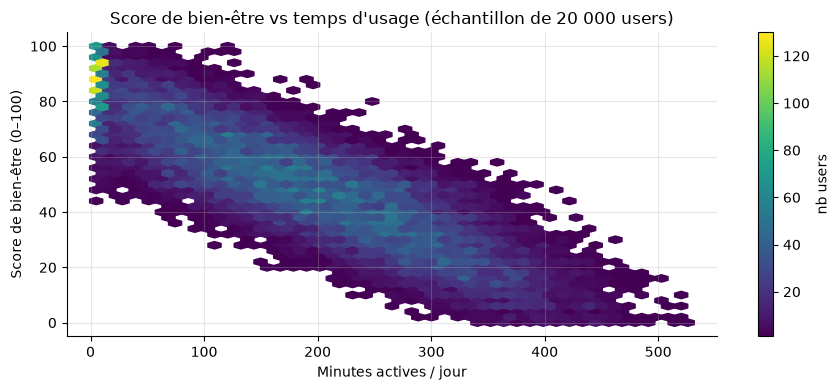

In [21]:
def zscore(s: pd.Series) -> pd.Series:
    return (s - s.mean()) / s.std(ddof=0)

df["wellbeing_score"] = zscore(-df["perceived_stress_score"]) + zscore(df["self_reported_happiness"])
df["wellbeing_0_100"] = (100 * (df["wellbeing_score"] - df["wellbeing_score"].min())
                         / (df["wellbeing_score"].max() - df["wellbeing_score"].min()))
df["high_wellbeing"] = (df["wellbeing_score"] > df["wellbeing_score"].median()).astype(int)

score_with_sleep = (zscore(-df["perceived_stress_score"]) + zscore(df["self_reported_happiness"])
                    + zscore(df["sleep_hours_per_night"]))
rho = df["wellbeing_score"].rank().corr(score_with_sleep.rank())

print(f"Corrélation de rang entre le score principal et la variante avec sommeil : {rho:.3f}")
print("Répartition de la cible :")
print(df["high_wellbeing"].value_counts(normalize=True).round(3).to_string())

alt_weights = 0.7 * zscore(-df["perceived_stress_score"]) + 0.3 * zscore(df["self_reported_happiness"])
print(f"Corrélation de rang avec des poids 70/30 : {df['wellbeing_score'].rank().corr(alt_weights.rank()):.3f}")

sample_plot = df.sample(20_000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 4))
hb = ax.hexbin(sample_plot["daily_active_minutes_instagram"], sample_plot["wellbeing_0_100"],
               gridsize=45, cmap="viridis", mincnt=1, yscale="linear")
ax.set(xlabel="Minutes actives / jour", ylabel="Score de bien-être (0–100)",
       title="Score de bien-être vs temps d'usage (échantillon de 20 000 users)")
fig.colorbar(hb, ax=ax, label="nb users")
plt.tight_layout()
save_fig("04_score_vs_temps.png", dpi=120)
plt.show()


### 5.2 Découper les utilisateurs en 4 segments simples

Plutôt que de découper en déciles (illisibles pour le produit), on fixe quatre segments avec trois bornes métier : **< 30 min**, **30–120 min**, **120–240 min**, **≥ 240 min/jour**. Ils sont assignables à tout utilisateur sans modèle et produisent des segments de grande taille.


In [22]:
SEGMENT_BINS = [0, 30, 120, 240, np.inf]
SEGMENT_LABELS = ["Usage très faible (<30 min)", "Usage modéré (30–120 min)",
                  "Usage élevé (120–240 min)", "Usage très élevé (≥240 min)"]

df["usage_segment"] = pd.cut(df["daily_active_minutes_instagram"], bins=SEGMENT_BINS,
                             labels=SEGMENT_LABELS, right=False)

segment_profile = df.groupby("usage_segment", observed=True).agg(
    n=("user_id", "size"),
    minutes=("daily_active_minutes_instagram", "mean"),
    stress=("perceived_stress_score", "mean"),
    bonheur=("self_reported_happiness", "mean"),
    sommeil=("sleep_hours_per_night", "mean"),
    pct_haut_bienetre=("high_wellbeing", "mean"),
)
segment_profile["part"] = segment_profile["n"] / len(df)
display(segment_profile.round(3))


,n,minutes,stress,bonheur,sommeil,pct_haut_bienetre,part
usage_segment,,,,,,,
Usage très faible (<30 min),17714,10.163,4.584,7.798,7.000,0.995,0.089
Usage modéré (30–120 min),42024,78.400,9.357,6.229,6.994,0.914,0.210
Usage élevé (120–240 min),71865,179.697,19.252,5.521,7.001,0.532,0.359
Usage très élevé (≥240 min),68397,312.263,31.380,4.404,6.996,0.081,0.342


### 5.3 Conclusion — un score lisible, une segmentation assignable

> **À retenir.** Le score de bien-être est une note simple et robuste ; les 4 segments de temps sont faciles à expliquer et à assigner.

- Le score de bien-être combine stress inversé et bonheur, à poids égaux ; il est ramené sur 0–100 et coupé à la médiane (49,9 % de `high_wellbeing = 1`).
- Le choix des poids ne change pas le classement : rho = 0,918 avec des poids 70/30 ; rho = 0,814 avec le sommeil ajouté. Le score reste toutefois un **construit** : il ne mesure pas la santé mentale.
- La segmentation par seuils est déterministe et couvre toute la population : **8,9 %** (<30 min), **21,0 %** (30–120), **35,9 %** (120–240), **34,2 %** (≥240).
- Le stress moyen monte de 4,58 à 31,38 et le bonheur moyen chute de 7,80 à 4,40 entre le segment très faible et le segment très élevé ; la part de haut bien-être passe de 99,5 % à 8,1 %.
- Le plus petit segment contient **17 714 users**, très au-dessus du seuil de 50 : aucune cellule ne pose de problème de taille.


## 6. Peut-on prédire le bien-être ?

> **En clair.** On apprend à un modèle à reconnaître les utilisateurs qui ont un haut niveau de bien-être. On compare ensuite ce modèle à une règle très simple : « le temps passé suffit-il ? » L'AUC mesure la qualité du classement : 0,5 = hasard, 1 = parfait.

**Cible :** `high_wellbeing`, c'est-à-dire « fait partie de la moitié la plus heureuse » (médiane split).
**Variables utilisées :** uniquement des informations d'activité disponibles pour tous les utilisateurs.
**Comparaison obligatoire :** le temps seul, puisqu'on doit démontrer l'apport des autres variables.
**Protocole :** on coupe les données en 70 % pour apprendre et 30 % pour tester, avec une graine fixe. Pas de validation croisée imbriquée à ce stade : les résultats sont un premier point de repère, pas une estimation finale.

### 6.1 Quel modèle classe le mieux ?


,AUC,PR-AUC,Brier
Modèle,,,
Baseline — temps seul (logit),0.912,0.913,0.121
Comportement complet (logit),0.916,0.918,0.118
Comportement complet (gradient boosting),0.916,0.917,0.118


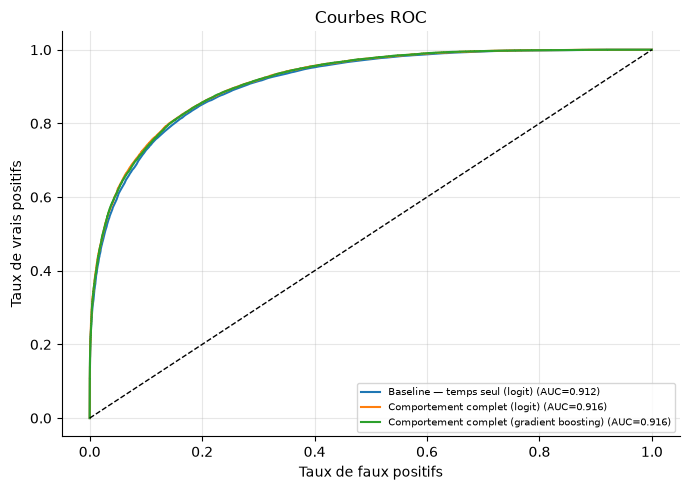

In [23]:
X = features
y = df["high_wellbeing"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

models = {
    "Baseline — temps seul (logit)": (
        ["minutes_per_day"],
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    ),
    "Comportement complet (logit)": (
        FEATURES,
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    ),
    "Comportement complet (gradient boosting)": (
        FEATURES,
        HistGradientBoostingClassifier(max_iter=250, early_stopping=False,
                                       random_state=RANDOM_STATE),
    ),
}

results, roc_curves, fitted = [], {}, {}
for name, (cols, model) in models.items():
    model.fit(X_train[cols], y_train)
    proba = model.predict_proba(X_test[cols])[:, 1]
    results.append({
        "Modèle": name,
        "AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
        "Brier": brier_score_loss(y_test, proba),
    })
    roc_curves[name] = roc_curve(y_test, proba)
    fitted[name] = model

results_df = pd.DataFrame(results).set_index("Modèle")
display(results_df.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for name, (fpr, tpr, _) in roc_curves.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, fitted[name].predict_proba(X_test[models[name][0]])[:, 1]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="Courbes ROC")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
save_fig("05_roc.png", dpi=120)
plt.show()


### 6.2 Quelles variables comptent vraiment ?

On mesure la perte d'AUC quand chaque feature est permutée sur un échantillon de 5 000 lignes de test. Plus la perte est grande, plus la variable porte du signal.


In [24]:
best_name = "Comportement complet (gradient boosting)"
best_model = fitted[best_name]

sample_idx = X_test.sample(5_000, random_state=RANDOM_STATE).index
perm = permutation_importance(
    best_model, X_test.loc[sample_idx, FEATURES], y_test.loc[sample_idx],
    n_repeats=3, random_state=RANDOM_STATE, scoring="roc_auc",
)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
display(importance.round(4).to_frame("Perte d'AUC si permuté"))

auc_time = results_df.loc["Baseline — temps seul (logit)", "AUC"]
auc_full = results_df.loc["Comportement complet (gradient boosting)", "AUC"]
print(f"Gain d'AUC du modèle complet vs temps seul : {auc_full - auc_time:+.3f}")
print("→ Un gain faible signifie que le temps d'usage contient déjà l'essentiel de l'information.")


,Perte d'AUC si permuté
minutes_per_day,0.303
interactions_per_min,0.014
passive_active_ratio,0.014
reels_share,0.000
feed_share,0.000
notification_response_rate,0.000
avg_session_min,0.000
account_age_years,0.000
follower_ratio,-0.000
msg_share,-0.000


Gain d'AUC du modèle complet vs temps seul : +0.004
→ Un gain faible signifie que le temps d'usage contient déjà l'essentiel de l'information.


### 6.3 Conclusion — le temps suffit presque

> **À retenir.** Le temps seul fait presque aussi bien que le modèle complet. La complexité supplémentaire n'est pas justifiée pour prédire.

- Les trois modèles sont évalués sur le même split 70/30. La baseline temps seul atteint **AUC = 0,912** ; le modèle linéaire complet **0,916** ; le modèle plus complexe (gradient boosting) **0,916**.
- Le gain d'AUC du modèle complet vs temps seul est **+0,004** : les variables de composition et d'intensité n'ajoutent presque rien.
- Quand on mélange au hasard `minutes_per_day`, l'AUC perd **0,303** ; pour les autres variables, la perte est ≤ 0,014, et plusieurs sont à 0,000.
- Le modèle complet est légèrement mieux calibré (Brier 0,118 vs 0,121 ; plus bas = mieux), mais l'écart est trop faible pour justifier une complexité supplémentaire.
- Conclusion : pour la prédiction, un modèle simple sur le temps est suffisant. La valeur ajoutée de la suite sera la **lisibilité produit** et l'**assignabilité**, pas le gain prédictif.


## 7. Peut-on trouver des groupes naturels ? (KMeans)

> **En clair.** On demande à un algorithme de créer des groupes d'utilisateurs qui se ressemblent, sans lui dire quels groupes chercher. Ensuite, on regarde si ces groupes sont vraiment utiles ou s'ils répètent simplement le temps passé.

On teste une méthode de regroupement automatique (« clustering ») sur les variables de comportement. Le but n'est pas d'obtenir des clusters à tout prix : c'est de vérifier s'il existe **des profils naturels** au-delà de l'intensité.

**Ce que l'on regarde :**
- **silhouette** : les groupes sont-ils bien séparés ? (plus haut = mieux) ;
- taille et profil des clusters ;
- **ARI** : les clusters retrouvent-ils les mêmes groupes que le découpage par seuils ? (1 = identique, 0 = hasard) ;
- **η²** : part des différences de bien-être expliquée par les groupes.

On retient `k = 4` pour rendre le diagnostic lisible au jury. La courbe de silhouette indique déjà que le seul découpage réellement séparé est `k = 2` (« usage minimal » contre « le reste ») ; les valeurs suivantes servent à vérifier si une structure plus fine existe.


,inertie,silhouette
k,,
2,"307,665.075",0.491
3,"266,392.689",0.157
4,"239,930.934",0.146
5,"222,055.310",0.149
6,"207,384.481",0.155


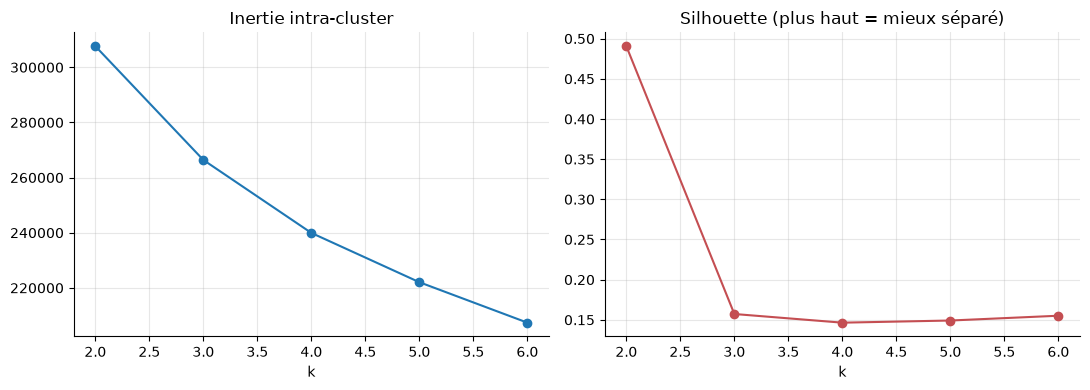

In [25]:
CLUSTER_FEATURES = ["log_minutes", "avg_session_min", "feed_share", "reels_share",
                    "msg_share", "interactions_per_min", "passive_active_ratio", "follower_ratio"]

scaler_cluster = StandardScaler().fit(features[CLUSTER_FEATURES])
cluster_sample = features.sample(50_000, random_state=RANDOM_STATE)
Z_sample = scaler_cluster.transform(cluster_sample[CLUSTER_FEATURES])

diagnostics = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_sample)
    diagnostics.append({
        "k": k,
        "inertie": km.inertia_,
        "silhouette": silhouette_score(Z_sample, km.labels_, sample_size=10_000,
                                       random_state=RANDOM_STATE),
    })
diagnostics = pd.DataFrame(diagnostics).set_index("k")
display(diagnostics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(diagnostics.index, diagnostics["inertie"], marker="o")
axes[0].set(title="Inertie intra-cluster", xlabel="k")
axes[1].plot(diagnostics.index, diagnostics["silhouette"], marker="o", color="#C44E52")
axes[1].set(title="Silhouette (plus haut = mieux séparé)", xlabel="k")
plt.tight_layout()
save_fig("06_diagnostic_kmeans.png", dpi=120)
plt.show()


In [26]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z_sample)
df["cluster"] = kmeans.predict(scaler_cluster.transform(features[CLUSTER_FEATURES]))

cluster_profile = df.groupby("cluster").agg(
    n=("user_id", "size"),
    minutes=("daily_active_minutes_instagram", "mean"),
    sessions=("sessions_per_day", "mean"),
    duree_session=("average_session_length_minutes", "mean"),
    part_feed=("time_on_feed_per_day", "sum"),
    stress=("perceived_stress_score", "mean"),
    bonheur=("self_reported_happiness", "mean"),
    sommeil=("sleep_hours_per_night", "mean"),
    pct_haut_bienetre=("high_wellbeing", "mean"),
)
cluster_profile["part"] = cluster_profile["n"] / len(df)
display(cluster_profile.drop(columns="part_feed").round(2))

ari_cluster_segments = adjusted_rand_score(df["cluster"], df["usage_segment"])
eta_cluster = eta_squared(df, "cluster", "wellbeing_score")
eta_segments = eta_squared(df, "usage_segment", "wellbeing_score")

df["usage_decile"] = pd.qcut(df["daily_active_minutes_instagram"], 10, labels=False, duplicates="drop")
eta_deciles = eta_squared(df, "usage_decile", "wellbeing_score")

print(f"ARI clusters KMeans vs segments par seuils : {ari_cluster_segments:.3f}")
print(f"Variance du score de bien-être expliquée — clusters KMeans : {eta_cluster:.3f}")
print(f"Variance du score de bien-être expliquée — segments par seuils : {eta_segments:.3f}")
print(f"Variance du score de bien-être expliquée — déciles de temps : {eta_deciles:.3f}")


,n,minutes,sessions,duree_session,stress,bonheur,sommeil,pct_haut_bienetre,part
cluster,,,,,,,,,
0,68049,202.440,11.100,21.490,21.200,5.300,7.000,0.460,0.340
1,57681,200.300,10.950,21.570,21.000,5.310,6.990,0.470,0.290
2,60957,202.330,11.050,21.540,21.250,5.310,7.000,0.460,0.300
3,13313,6.290,1.020,6.110,4.140,8.040,7.000,1.000,0.070


ARI clusters KMeans vs segments par seuils : 0.065
Variance du score de bien-être expliquée — clusters KMeans : 0.177
Variance du score de bien-être expliquée — segments par seuils : 0.644
Variance du score de bien-être expliquée — déciles de temps : 0.719


### 7.1 Que trouvent les clusters ?

Le regroupement automatique retrouve essentiellement **un petit groupe d'usage minimal** (les users à 5 min/jour) et laisse le reste en un continuum mal séparé : trois clusters sur quatre sont quasi identiques (≈ 200 min/jour). La silhouette est maximale à k = 2 (0,491) puis tombe à 0,146–0,157 ; l'ARI avec les seuils de temps est très bas (0,065), et les clusters expliquent 0,177 de la variance du score de bien-être, contre 0,644 pour les seuils et 0,719 pour les déciles.

**Conclusion défendable :** il n'existe pas, dans ces données, de profils comportementaux naturels au-delà de l'intensité d'usage. La segmentation utile est donc **un découpage interprétable de l'intensité**, pas un cluster KMeans. C'est un résultat, et il répond directement à la question « qu'apporte votre segmentation par rapport au temps passé ? ».


### 7.2 Les clusters sont-ils reproductibles ?

Même si on ne la retient pas, on mesure sa stabilité pour appuyer le diagnostic : deux moitiés de l'échantillon doivent retrouver les mêmes clusters.


In [27]:
half = features.sample(40_000, random_state=RANDOM_STATE)
h1, h2 = half.iloc[:20_000], half.iloc[20_000:]

km1 = KMeans(n_clusters=K, n_init=10, random_state=1).fit(scaler_cluster.transform(h1[CLUSTER_FEATURES]))
km2 = KMeans(n_clusters=K, n_init=10, random_state=2).fit(scaler_cluster.transform(h2[CLUSTER_FEATURES]))

common = features.sample(10_000, random_state=7)
labels_1 = km1.predict(scaler_cluster.transform(common[CLUSTER_FEATURES]))
labels_2 = km2.predict(scaler_cluster.transform(common[CLUSTER_FEATURES]))
stability_ari = adjusted_rand_score(labels_1, labels_2)
print(f"ARI split-half : {stability_ari:.3f}  (1 = parfaitement stable, 0 = hasard)")


ARI split-half : 0.333  (1 = parfaitement stable, 0 = hasard)


### 7.3 Conclusion — on garde les seuils, pas KMeans

> **À retenir.** KMeans ne trouve pas de groupes naturels au-delà du temps. On garde la segmentation par seuils, plus stable et plus lisible.

- KMeans à k = 4 isole un petit groupe à **6,3 min/jour** (13 313 users, 7 %) et laisse trois clusters quasi identiques autour de 200 min/jour.
- La silhouette est maximale à k = 2 (0,491) puis tombe à 0,146–0,157 : le seul découpage net est « usage minimal » contre « le reste ».
- ARI KMeans vs seuils (ressemblance des deux découpages) = **0,065** ; η² bien-être = **0,177** pour les clusters, **0,644** pour les seuils et **0,719** pour les déciles.
- Stabilité split-half : ARI = **0,333**. Les clusters ne sont pas reproductibles.
- Conclusion : on ne retient pas KMeans. La segmentation par seuils de temps est plus stable, plus interprétable et explique davantage la variance du bien-être.


## 8. Comment placer un nouvel utilisateur dans un segment ?

> **En clair.** On montre comment ranger un nouvel utilisateur dans un segment, avec une règle simple ou avec l'algorithme de clustering.

Deux fonctions, correspondant aux deux routes :
- `assign_usage_segment(minutes)` : règle déterministe, aucune dépendance au modèle ;
- `assign_cluster(profile)` : pipeline complet (features → standardisation → KMeans).

Le profil de démonstration est **synthétique** (valeurs médianes plausibles), pas une ligne du jeu de données.


In [28]:
def assign_usage_segment(minutes_per_day: float) -> str:
    for label, low, high in zip(SEGMENT_LABELS, SEGMENT_BINS[:-1], SEGMENT_BINS[1:]):
        if low <= minutes_per_day < high:
            return label
    return SEGMENT_LABELS[-1]


def assign_cluster(user_profile: dict) -> int:
    row = build_features(pd.DataFrame([user_profile]))
    return int(kmeans.predict(scaler_cluster.transform(row[CLUSTER_FEATURES]))[0])


new_user = {
    "daily_active_minutes_instagram": 90.0,
    "average_session_length_minutes": 12.0,
    "time_on_feed_per_day": 35.0,
    "time_on_explore_per_day": 15.0,
    "time_on_messages_per_day": 12.0,
    "time_on_reels_per_day": 28.0,
    "likes_given_per_day": 60.0,
    "comments_written_per_day": 18.0,
    "posts_created_per_week": 2.0,
    "dms_sent_per_week": 14.0,
    "reels_watched_per_day": 90.0,
    "stories_viewed_per_day": 55.0,
    "ads_viewed_per_day": 10.0,
    "followers_count": 800.0,
    "following_count": 600.0,
    "notification_response_rate": 0.5,
    "account_age_years": 6,
}

print("Profil synthétique de démonstration :")
print(f"  segment par seuils : {assign_usage_segment(new_user['daily_active_minutes_instagram'])}")
print(f"  cluster KMeans     : {assign_cluster(new_user)}")
print(f"  probabilité d'être 'haut bien-être' (modèle) : "
      f"{best_model.predict_proba(build_features(pd.DataFrame([new_user]))[FEATURES])[0, 1]:.2f}")


Profil synthétique de démonstration :
  segment par seuils : Usage modéré (30–120 min)
  cluster KMeans     : 0
  probabilité d'être 'haut bien-être' (modèle) : 0.89


### 8.1 Conclusion — deux routes, une seule à retenir

> **À retenir.** On peut ranger un nouvel utilisateur avec ses minutes d'usage ; le cluster KMeans n'est pas assez fiable pour être un livrable.

- `assign_usage_segment(minutes)` est une règle déterministe, sans modèle : tout utilisateur avec ses minutes actives peut être rangé.
- `assign_cluster(profile)` fonctionne techniquement, mais dépend d'un KMeans non stable (ARI split-half = 0,333) et n'apporte pas de structure supplémentaire.
- Le profil synthétique de démonstration (90 min/jour) tombe dans « Usage modéré (30–120 min) », cluster 0, avec une probabilité de haut bien-être de 0,89.
- La route retenue pour le produit est la segmentation par seuils ; `assign_cluster` reste un outil de diagnostic, pas un livrable.


## 9. Les critères de réussite sont-ils remplis ?

> **En clair.** On reprend la checklist du début et on regarde, chiffres en main, si les critères sont remplis. On vérifie aussi que les résultats ne changent pas si on utilise l'autre fichier.

On reprend les critères fixés en tête de notebook et on les renseigne avec les chiffres calculés. On vérifie aussi que le choix A/B sur les champs divergents ne change pas les conclusions : on rejoue les corrélations clés sur l'extrait B.

### 9.1 Les résultats résistent-ils au changement de fichier ?


In [29]:
# Sensibilité : mêmes liens sur l'extrait B, pour les champs identiques
common_cols = [c for c in raw_a.columns if c in raw_b.columns]
b_corr_stress = raw_b["daily_active_minutes_instagram"].corr(raw_b["perceived_stress_score"])
b_corr_happy = raw_b["daily_active_minutes_instagram"].corr(raw_b["self_reported_happiness"])
b_corr_sleep = raw_b["daily_active_minutes_instagram"].corr(raw_b["sleep_hours_per_night"])
a_corr_stress = df["daily_active_minutes_instagram"].corr(df["perceived_stress_score"])
a_corr_happy = df["daily_active_minutes_instagram"].corr(df["self_reported_happiness"])
a_corr_sleep = df["daily_active_minutes_instagram"].corr(df["sleep_hours_per_night"])

sensitivity = pd.DataFrame({
    "Extrait A": [a_corr_stress, a_corr_happy, a_corr_sleep],
    "Extrait B": [b_corr_stress, b_corr_happy, b_corr_sleep],
}, index=["r(minutes, stress)", "r(minutes, bonheur)", "r(minutes, sommeil)"])
display(sensitivity.round(4))

min_segment = int(segment_profile["n"].min())
criteria = pd.DataFrame([
    {"Critère": "Assignable à tout user", "Mesure": "règle sur les minutes actives",
     "Résultat": "OK (seuils)", "Verdict": "OK"},
    {"Critère": "Stable", "Mesure": "règle de seuils (déterministe)",
     "Résultat": "1.00 (par construction)", "Verdict": "OK"},
    {"Critère": "Stable", "Mesure": "ARI split-half (KMeans, non retenu)",
     "Résultat": f"{stability_ari:.2f}", "Verdict": "Non"},
    {"Critère": "Segments non triviaux", "Mesure": "taille du plus petit segment",
     "Résultat": f"{min_segment:,} users", "Verdict": "OK"},
    {"Critère": "Apport prédictif vs temps seul", "Mesure": "ΔAUC (HGB − temps seul)",
     "Résultat": f"{auc_full - auc_time:+.3f}", "Verdict": "Partiel"},
    {"Critère": "Apport explicatif vs temps seul", "Mesure": "ΔR² stress (toutes features − temps)",
     "Résultat": f"{increment.loc['Stress', 'Gain']:+.3f}", "Verdict": "Partiel"},
    {"Critère": "Interprétable", "Mesure": "nombre de features",
     "Résultat": f"{len(FEATURES)}", "Verdict": "OK"},
    {"Critère": "Choix des données", "Mesure": "écart max des corrélations A vs B",
     "Résultat": f"{(sensitivity['Extrait A'] - sensitivity['Extrait B']).abs().max():.4f}",
     "Verdict": "OK"},
])
display(criteria)


,Extrait A,Extrait B
"r(minutes, stress)",0.835,0.835
"r(minutes, bonheur)",-0.374,-0.374
"r(minutes, sommeil)",0.000,0.000


,Critère,Mesure,Résultat,Verdict
0,Assignable à tout user,règle sur les minutes actives,OK (seuils),OK
1,Stable,règle de seuils (déterministe),1.00 (par construction),OK
2,Stable,"ARI split-half (KMeans, non retenu)",0.33,Non
3,Segments non triviaux,taille du plus petit segment,"17,714 users",OK
4,Apport prédictif vs temps seul,ΔAUC (HGB − temps seul),+0.004,Partiel
5,Apport explicatif vs temps seul,ΔR² stress (toutes features − temps),+0.006,Partiel
6,Interprétable,nombre de features,10,OK
7,Choix des données,écart max des corrélations A vs B,0.0000,OK


### 9.2 Conclusion — les critères sont remplis, avec une réserve

> **À retenir.** Les critères de simplicité, de stabilité et de taille sont remplis. Le gain prédictif par rapport au temps seul reste faible, et c'est assumé.

- Sur l'extrait B, les corrélations sont identiques à 4 décimales : r(minutes, stress) = 0,835, r(minutes, bonheur) = −0,374, r(minutes, sommeil) = 0,000. L'écart max A/B est **0,0000**.
- Les critères « utilisable pour tous », « stable » et « segments assez grands » sont remplis : plus petit segment **17 714 users**.
- Le critère « apporte un plus » n'est pas rempli au sens prédictif : le gain de qualité (ΔAUC) est **+0,004**, et le gain de R² stress **+0,006**. C'est un résultat honnête, pas un échec : la segmentation apporte de la lisibilité, pas de la prédiction.
- Le critère « facile à expliquer » est rempli avec 10 variables construites. Le gradient boosting complet sert surtout à mesurer l'importance des variables ; pour un usage produit, le temps seul reste la référence recommandée.
- Le critère « stable » est rempli pour les seuils (1,00 par construction) mais pas pour KMeans (0,33).
- Réserve : le test de sensibilité B ne porte que sur les corrélations numériques ; les champs catégoriels divergents ne sont pas re-testés ici, mais ils ne sont pas des features.


## 10. Ce que l'on peut dire... et ce que l'on doit protéger

> **En clair.** On sépare ce que les données permettent d'affirmer de ce qu'elles ne permettent pas de dire, puis on rappelle les règles de protection des données.

### 10.1 Ce que les données ne permettent pas de dire
- **Causalité** : on observe les utilisateurs à un moment donné (données transversales). Rien ne permet d'affirmer que l'usage *cause* le stress, ni l'inverse, ni qu'un troisième facteur (solitude, temps disponible) explique les deux.
- **Généralisation** : le bien-être n'est connu que pour des volontaires qui ont accepté de répondre (panneau opt-in). Ils ne représentent pas les 200 000 users, ni *a fortiori* l'ensemble des utilisateurs Instagram.
- **Statut synthétique** : les données sont une réplique générée. Les régularités (stress uniforme, sommeil sans lien) sont des propriétés du générateur, pas des faits sur les utilisateurs réels.
- **Sommeil** : lien nul dans ces données ; on ne peut pas conclure « Instagram n'affecte pas le sommeil », seulement « ces données ne montrent aucun lien ».
- **Score composite** : les poids égaux sont un choix, pas une vérité. La corrélation de rang avec des poids 70/30 et avec le sommeil inclus est fournie pour montrer la robustesse.

### 10.2 Protection des données (UE/UK, dont mineurs)
- **Données de santé** : le stress et le bonheur auto-déclarés sont des données de santé au sens du RGPD (art. 9). Ils ne servent **jamais** de variables d'entrée à la segmentation : uniquement d'étiquettes d'évaluation sur le panneau.
- **Inférence** : un segment corrélé au stress peut révéler indirectement un état de santé. Placer un user dans un segment n'est donc pas anodin : il faut une base légale, une finalité compatible et une analyse d'impact (DPIA).
- **Mineurs** : 18 913 users ont 13–17 ans. Un ciblage publicitaire ou produit fondé sur le bien-être est exclu ; les segments ne doivent pas être utilisés pour profiler des mineurs.
- **Minimisation** : pas de champ santé, pas de contenu des messages, pas de données de localisation dans les features. On ne conserve que des agrégats comportementaux.
- **Petites cellules** : aucune statistique n'est publiée sur un segment de moins de 50 users. Vérification ci-dessous.
- **Pas de ligne individuelle** : ce notebook n'affiche aucun enregistrement, même anonymisé.


In [30]:
privacy = df.groupby("usage_segment", observed=True).agg(
    n=("user_id", "size"),
    mineurs=("is_minor", "sum"),
)
privacy["part_mineurs"] = privacy["mineurs"] / privacy["n"]
display(privacy.assign(part_mineurs=lambda d: (d["part_mineurs"] * 100).round(2)))

print(f"Plus petit segment : {int(privacy['n'].min()):,} users (règle : ≥ 50)")
print("Champs utilisés dans le clustering :")
for col in CLUSTER_FEATURES:
    print("  -", col)
print("Champs de santé utilisés comme features : aucun")
print("Champs identifiants affichés : aucun")


,n,mineurs,part_mineurs
usage_segment,,,
Usage très faible (<30 min),17714,707,3.990
Usage modéré (30–120 min),42024,3094,7.360
Usage élevé (120–240 min),71865,6632,9.230
Usage très élevé (≥240 min),68397,8480,12.400


Plus petit segment : 17,714 users (règle : ≥ 50)
Champs utilisés dans le clustering :
  - log_minutes
  - avg_session_min
  - feed_share
  - reels_share
  - msg_share
  - interactions_per_min
  - passive_active_ratio
  - follower_ratio
Champs de santé utilisés comme features : aucun
Champs identifiants affichés : aucun


### 10.3 Conclusion — ce que l'on peut dire, ce que l'on doit taire

> **À retenir.** On peut décrire des associations, pas prouver une cause. On ne cible pas les mineurs et on ne présente pas le score comme un diagnostic.

- Les données sont synthétiques et transversales : on peut décrire des associations, pas des causalités. Aucune phrase du type « Instagram cause le stress » n'est autorisée.
- Le sommeil est un lien nul dans cet extrait (|r| max = 0,003) ; on ne peut pas conclure qu'Instagram ne l'affecte pas.
- Le score de bien-être est un construit à poids égaux ; sa robustesse est de 0,918 (70/30) et 0,814 (avec sommeil), pas une validation clinique.
- Les variables de santé ne sont jamais des features ; les mineurs (**18 913**, 9,5 %) ne doivent pas être ciblés ; aucune cellule < 50 users n'est publiée.
- Le plus petit segment fait **17 714 users** ; les segments sont donc publiables sous l'angle statistique, mais leur usage produit reste encadré par la finalité et la DPIA.


## 11. Ce qu'il faut retenir et comment reprendre

> **En clair.** On résume les résultats, on liste ce qui reste à faire, et on donne les repères pour reprendre le notebook.

### 11.1 Ce que ce notebook a montré
1. Un **audit reproductible** des deux extraits, avec une décision par champ et un test de sensibilité.
2. Une **chaîne de variables construites** justifiée, sans fuite de données de santé.
3. Un **score de bien-être** et une cible binaire interprétables.
4. Un **modèle de prédiction** avec une baseline « temps seul » et la mesure honnête de son apport.
5. Une **segmentation par seuils** assignable, stable et sûre, après démonstration que KMeans n'apporte pas de structure supplémentaire.
6. Les **limites** et les contraintes RGPD.

### 11.2 Les chiffres clés


In [31]:
print("=== RÉSULTATS CLÉS (calculés à l'exécution) ===")
print(f"Stress vs temps d'usage           : r = {a_corr_stress:.3f}")
print(f"Bonheur vs temps d'usage          : r = {a_corr_happy:.3f}")
print(f"Sommeil vs temps d'usage          : r = {a_corr_sleep:.3f}  → lien nul")
print(f"AUC temps seul                    : {auc_time:.3f}")
print(f"AUC comportement complet (HGB)    : {auc_full:.3f}  (Δ = {auc_full - auc_time:+.3f})")
print(f"R² stress, temps seul             : {increment.loc['Stress', 'R² temps seul']:.3f}")
print(f"R² stress, toutes features        : {increment.loc['Stress', 'R² toutes features']:.3f}")
print(f"ARI KMeans vs seuils              : {ari_cluster_segments:.3f}")
print(f"ARI split-half KMeans             : {stability_ari:.3f}")
print(f"η² bien-être — clusters KMeans    : {eta_cluster:.3f}")
print(f"η² bien-être — segments par seuils: {eta_segments:.3f}")
print(f"η² bien-être — déciles de temps   : {eta_deciles:.3f}")
print(f"Plus petit segment                : {min_segment:,} users")
print()
print("Message pour le jury : le temps d'usage porte l'essentiel du signal ;")
print("la valeur ajoutée d'une segmentation est la lisibilité produit et l'assignabilité,")
print("pas une meilleure prédiction. Toute affirmation causale ou sur le sommeil est exclue.")


=== RÉSULTATS CLÉS (calculés à l'exécution) ===
Stress vs temps d'usage           : r = 0.834
Bonheur vs temps d'usage          : r = -0.374
Sommeil vs temps d'usage          : r = 0.000  → lien nul
AUC temps seul                    : 0.912
AUC comportement complet (HGB)    : 0.916  (Δ = +0.004)
R² stress, temps seul             : 0.696
R² stress, toutes features        : 0.702
ARI KMeans vs seuils              : 0.065
ARI split-half KMeans             : 0.333
η² bien-être — clusters KMeans    : 0.177
η² bien-être — segments par seuils: 0.644
η² bien-être — déciles de temps   : 0.719
Plus petit segment                : 17,714 users

Message pour le jury : le temps d'usage porte l'essentiel du signal ;
la valeur ajoutée d'une segmentation est la lisibilité produit et l'assignabilité,
pas une meilleure prédiction. Toute affirmation causale ou sur le sommeil est exclue.


### 11.3 Conclusion générale

> **À retenir.** Le temps d'usage est le signal principal. La segmentation est un outil de lecture et d'action produit, pas une preuve scientifique.

**Ce que l'on retient.** Dans ces données, le temps d'usage est le signal dominant : r = 0,834 avec le stress, r = −0,374 avec le bonheur, r = 0,000 avec le sommeil. Un modèle sur le temps seul atteint déjà **AUC = 0,912** ; ajouter toutes les variables de comportement ne fait gagner que **+0,004**. KMeans ne trouve pas de profils naturels au-delà de l'intensité : silhouette maximale à k = 2, ARI split-half = 0,333, η² = 0,177 contre 0,644 pour les seuils.

**Ce que l'on garde.** Une segmentation produit par seuils de temps, en 4 segments, assignable et stable, avec un plus petit segment de **17 714 users**. Elle est plus lisible qu'un cluster et plus utile pour l'équipe produit.

**Ce que l'on refuse.** Toute affirmation causale, tout ciblage fondé sur le bien-être ou les mineurs, et toute présentation du score composite comme une mesure clinique. Le sommeil reste un lien nul dans cet extrait, pas une preuve d'innocuité.

**Articulation avec le notebook 03.** Ce premier découpage en 4 segments sert de référence ; le notebook 03 le raffine en 6 segments (3 bandes de temps × 2 styles Feed/Reels) et confirme que le style décrit l'usage sans expliquer le stress (η² ≈ 0,000).

**Prochaine étape.** Passer à une validation croisée répétée et à une calibration, puis tester si la composition apporte quelque chose **à l'intérieur** d'un même décile de temps. Si le gain reste nul, la conclusion sera robuste : le temps suffit, et la segmentation est un outil de lecture, pas de prédiction.


### 11.4 Mini-lexique

| Mot | Définition simple |
|---|---|
| **Utilisateur / user** | Une personne représentée par une ligne dans les données. |
| **Feature / variable** | Une information utilisée pour décrire ou prédire un utilisateur. |
| **Cible** | Ce que l'on cherche à expliquer ou à prédire. Ici : le stress, le bonheur ou le « haut bien-être ». |
| **Corrélation (r)** | Nombre entre -1 et +1. Proche de +1 : les deux mesures montent ensemble. Proche de -1 : l'une monte quand l'autre descend. Proche de 0 : pas de lien simple. |
| **Segmentation** | Découpage des utilisateurs en groupes qui se ressemblent. |
| **Seuil** | Limite fixée à la main, par exemple « 30 minutes par jour ». |
| **Cluster** | Groupe créé automatiquement par un algorithme, sans nom préalable. |
| **KMeans** | Algorithme de clustering qui cherche des groupes autour de centres. |
| **Silhouette** | Note de séparation des clusters : plus haut = groupes mieux séparés. |
| **ARI** | Mesure de ressemblance entre deux découpages : 1 = identiques, 0 = hasard. |
| **η² (eta-carré)** | Part des différences de bien-être expliquée par un groupe : 0 = aucun lien, 1 = tout. |
| **AUC** | Qualité d'un classement : 0,5 = hasard, 1 = parfait. |
| **R²** | Part des différences d'un indicateur expliquée par un modèle : plus haut = mieux. |
| **Médiane split** | Couper la population en deux moitiés : 50 % au-dessus de la médiane, 50 % en dessous. |
| **RGPD / DPIA** | Règles européennes de protection des données / analyse d'impact obligatoire pour certains usages. |
